# 2 · A first look at the data

A quick exploration: where the wells are, what the three cubes look like around them, the
porosity logs, and how the cube values relate to porosity at the wells.

This is description, not modelling. The pooled correlations at the end are not a
performance estimate (see the validation note in notebook 1).

In [1]:
import os
import numpy as np
import pandas as pd
from volve_mlready import VolveMLReady

# folder holding the files downloaded from Zenodo
DATA = os.environ.get('VOLVE_MLREADY_DIR', '../data/volve-mlready-v1.0.0')
v = VolveMLReady(DATA)

import matplotlib.pyplot as plt
import viz_style as vs
vs.apply()

amp, vp, pp = v.cube('ps_amplitude'), v.cube('vp'), v.cube('pp_amplitude')
idx, vox, smp = v.wells('index'), v.wells('voxels'), v.wells('samples')
g = v.grid
FIG = '../docs/figures'
os.makedirs(FIG, exist_ok=True)

def short(name):              # '15/9-F-11B' -> 'F-11B', '15/9-19 A' -> '19 A'
    return name.replace('15/9-', '')

## Where the wells are

A depth slice of the PS amplitude at 2950 m below MSL, close to the reservoir. Thin lines are
the full well paths from the surface. Thick lines are the sections with porosity data. The
right panel zooms in on the platform area, where most wells cluster.

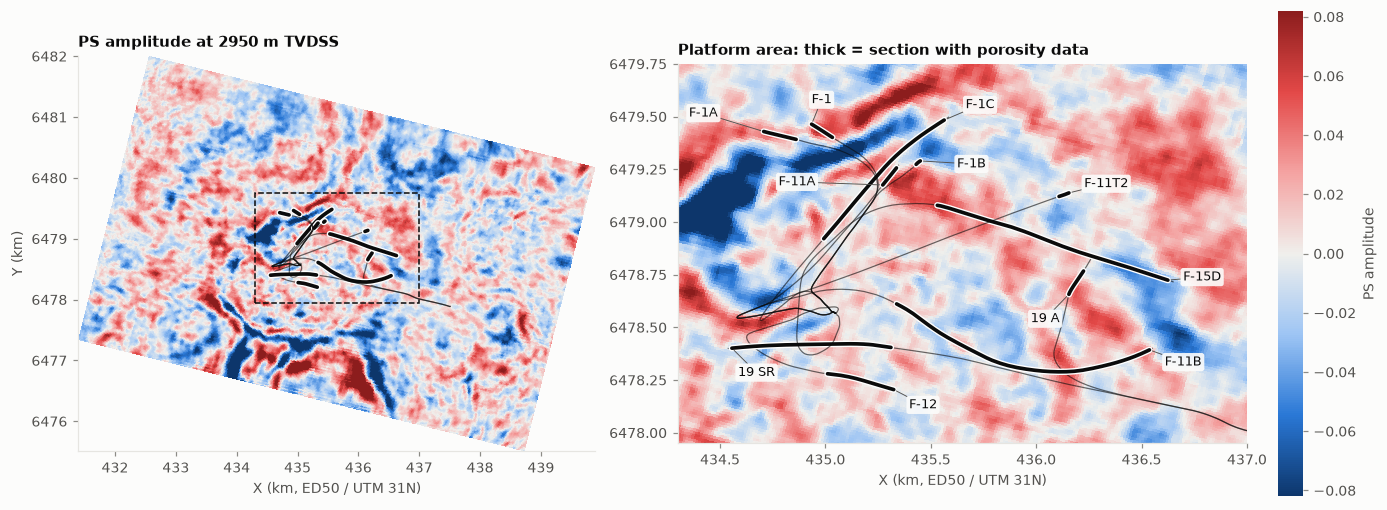

In [2]:
z_slice = 2950
iz = int(round((z_slice - g['z0']) / g['dz']))
IL, XL = np.meshgrid(g['ilines'], g['xlines'], indexing='ij')
GX, GY = v.ilxl_to_xy(IL, XL)
sl = np.asarray(amp[iz])
lo, hi = vs.sym_limits(sl)
ZOOM = (434.3, 437.0, 6477.95, 6479.75)          # km: x0, x1, y0, y1

# label placement for the crowded platform area: (anchor, dx, dy) in points
LABEL = {'F-1A': ('end', -30, 12), 'F-1': ('end', 0, 16), 'F-1C': ('end', 14, 10),
         'F-1B': ('end', 24, -2), 'F-11A': ('start', -44, 2), 'F-11T2': ('end', 10, 6),
         'F-15D': ('end', 10, 2), '19 A': ('start', -6, -16), 'F-11B': ('end', 10, -8),
         '19 SR': ('end', 4, -16), 'F-12': ('end', 10, -10)}

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12.5, 5.6), width_ratios=[1, 1.1],
                               constrained_layout=True)
for ax in (ax0, ax1):
    m = ax.pcolormesh(GX / 1e3, GY / 1e3, sl, cmap='seismic_div', vmin=lo, vmax=hi,
                      shading='auto', rasterized=True)
    for r in idx.itertuples():
        t = v.trajectory(r.npd)
        ax.plot(t.X / 1e3, t.Y / 1e3, color=vs.INK, lw=0.8, alpha=0.6)
        s = smp[smp.npd == r.npd].sort_values('MD')
        ax.plot(s.X / 1e3, s.Y / 1e3, color='white', lw=4.2, solid_capstyle='round')
        ax.plot(s.X / 1e3, s.Y / 1e3, color=vs.INK, lw=2.4, solid_capstyle='round')
        if ax is ax1:
            name = short(r.wellbore)
            where, dx, dy = LABEL[name]
            k = -1 if where == 'end' else 0
            ax.annotate(name, (s.X.iloc[k] / 1e3, s.Y.iloc[k] / 1e3), xytext=(dx, dy),
                        textcoords='offset points', fontsize=8.5, color=vs.INK,
                        ha='left' if dx >= 0 else 'right', va='center',
                        arrowprops=dict(arrowstyle='-', color=vs.INK2, lw=0.6, shrinkA=0, shrinkB=2),
                        bbox=dict(boxstyle='round,pad=0.2', fc=vs.SURFACE, ec='none', alpha=0.9))
    ax.set_aspect('equal')
    ax.set_xlabel('X (km, ED50 / UTM 31N)')
x0, x1, y0, y1 = ZOOM
ax0.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=vs.INK, lw=1, ls='--'))
ax0.set_ylabel('Y (km)')
ax0.set_title(f'PS amplitude at {z_slice} m TVDSS')
ax1.set_xlim(x0, x1)
ax1.set_ylim(y0, y1)
ax1.set_title('Platform area: thick = section with porosity data')
cb = fig.colorbar(m, ax=ax1, shrink=0.8, pad=0.02)
cb.set_label('PS amplitude')
cb.outline.set_visible(False)
fig.savefig(f'{FIG}/map_wells.png')
plt.show()

## The three cubes along one inline

Inline 10214 crosses the F-1 cluster and F-11 T2. The panels show the same section in each
cube, with the well voxels that lie within ±2 inlines.

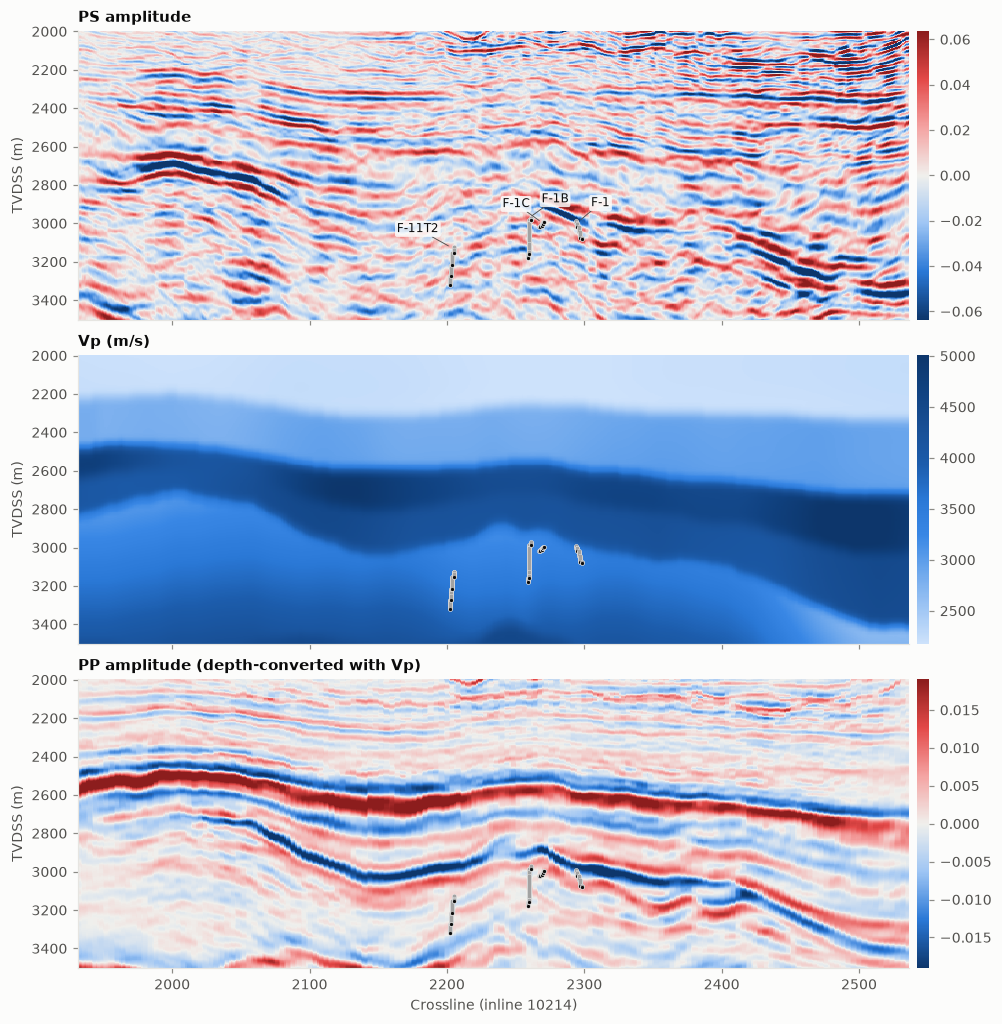

In [3]:
iy = 229
il_no = g['il0'] + iy
zr = slice(int(2000 / g['dz']), int(3500 / g['dz']) + 1)
depth = np.asarray(g['depths'])[zr]
xls = np.asarray(g['xlines'])
near = vox[(vox.IY - iy).abs() <= 2]

panels = [('PS amplitude', amp, 'seismic_div', True),
          ('Vp (m/s)', vp, 'blue_seq', False),
          ('PP amplitude (depth-converted with Vp)', pp, 'seismic_div', True)]
fig, axes = plt.subplots(3, 1, figsize=(9, 9.2), sharex=True, constrained_layout=True)
for ax, (title, cube, cmap, div) in zip(axes, panels):
    sec = np.asarray(cube[zr, iy, :])
    lim = vs.sym_limits(sec) if div else (np.percentile(sec, 1), np.percentile(sec, 99))
    m = ax.pcolormesh(xls, depth, sec, cmap=cmap, vmin=lim[0], vmax=lim[1],
                      shading='auto', rasterized=True)
    ax.scatter(g['xl0'] + near.IX, g['z0'] + near.IZ * g['dz'], s=7, color=vs.INK,
               edgecolor='white', linewidth=0.4, zorder=3)
    ax.invert_yaxis()
    ax.set_ylabel('TVDSS (m)')
    ax.set_title(title)
    cb = fig.colorbar(m, ax=ax, pad=0.01, aspect=25)
    cb.outline.set_visible(False)
tops = near.groupby('wellbore').agg(IX=('IX', 'median'), IZ=('IZ', 'min')).sort_values('IX')
for k, (name, d) in enumerate(tops.iterrows()):
    right = k % 2 == 1                     # alternate sides so neighbours do not collide
    axes[0].annotate(short(name), (g['xl0'] + d.IX, g['z0'] + d.IZ * g['dz']),
                     xytext=(8 if right else -8, 10), textcoords='offset points', fontsize=8,
                     ha='left' if right else 'right',
                     arrowprops=dict(arrowstyle='-', color=vs.INK2, lw=0.6, shrinkA=0, shrinkB=2),
                     bbox=dict(boxstyle='round,pad=0.15', fc=vs.SURFACE, ec='none', alpha=0.85))
axes[-1].set_xlabel(f'Crossline (inline {il_no})')
fig.savefig(f'{FIG}/section_three_cubes.png')
plt.show()

## Porosity logs

`PHIE` against depth for each well. Light blue points are the original log samples
(0.1–0.15 m step) and black dots are the 5 m voxel means used for training. Horizontal
wells stack many samples at almost the same depth.

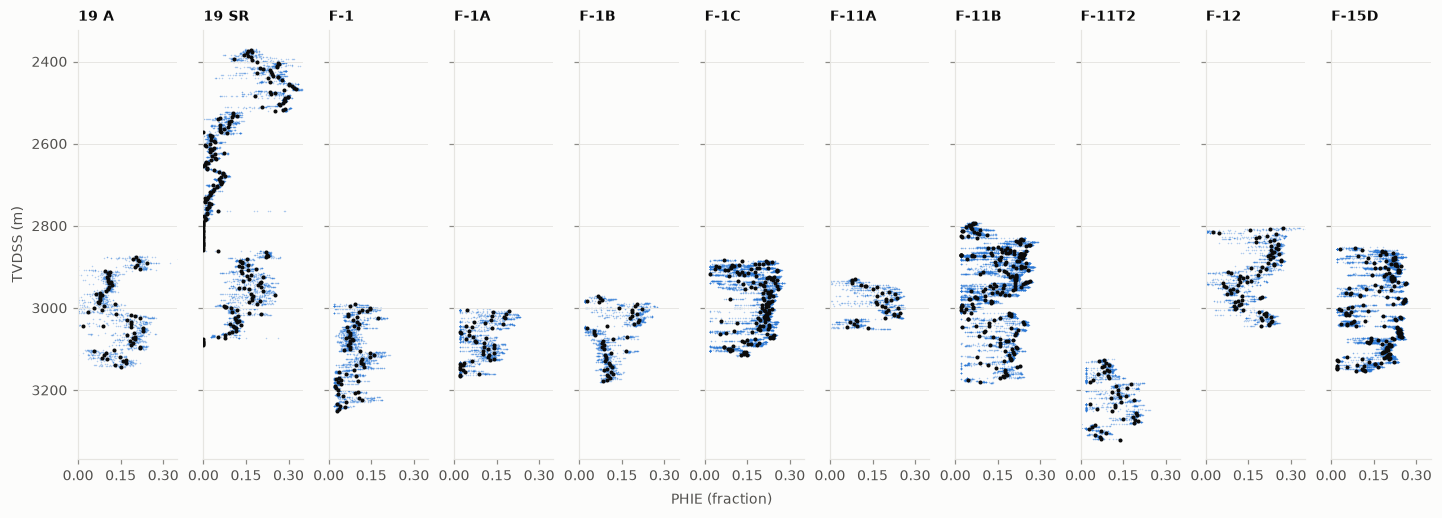

In [4]:
ORDER = ['15/9-19 A', '15/9-19 SR', '15/9-F-1', '15/9-F-1A', '15/9-F-1B', '15/9-F-1C',
         '15/9-F-11A', '15/9-F-11B', '15/9-F-11T2', '15/9-F-12', '15/9-F-15D']
order = idx.set_index('wellbore').loc[ORDER, 'npd'].tolist()
fig, axes = plt.subplots(1, len(order), figsize=(13, 4.6), sharey=True, constrained_layout=True)
for ax, npd in zip(axes, order):
    s = smp[smp.npd == npd].sort_values('MD')
    d = vox[vox.npd == npd]
    ax.scatter(s.PHIE, s.TVDSS, s=1, color=vs.BLUE, alpha=0.35, linewidth=0, rasterized=True)
    ax.scatter(d.PHIE, d.TVDSS, s=7, color=vs.INK, zorder=3, linewidth=0)
    ax.set_title(short(d.wellbore.iloc[0]), fontsize=9)
    ax.set_xlim(0, 0.35)
    ax.set_xticks([0, 0.15, 0.3])
    ax.grid(axis='y')
axes[0].invert_yaxis()
axes[0].set_ylabel('TVDSS (m)')
fig.supxlabel('PHIE (fraction)', fontsize=9, color=vs.INK2)
fig.savefig(f'{FIG}/phie_logs.png')
plt.show()

In [5]:
summary = (vox.groupby('wellbore')
              .agg(voxels=('PHIE', 'size'), PHIE_mean=('PHIE', 'mean'), PHIE_std=('PHIE', 'std'),
                   TVDSS_top=('TVDSS', 'min'), TVDSS_base=('TVDSS', 'max'))
              .round(3))
summary

,voxels,PHIE_mean,PHIE_std,TVDSS_top,TVDSS_base
wellbore,,,,,
15/9-19 A,68,0.140,0.057,2875.627,3142.949
15/9-19 SR,217,0.108,0.095,2371.363,3090.071
15/9-F-1,65,0.082,0.037,2991.578,3249.759
15/9-F-11A,36,0.160,0.059,2929.657,3050.000
15/9-F-11B,207,0.155,0.072,2792.119,3179.910
15/9-F-11T2,46,0.110,0.051,3126.326,3320.422
15/9-F-12,77,0.174,0.064,2805.894,3043.558
15/9-F-15D,160,0.166,0.070,2853.900,3152.676
15/9-F-1A,46,0.090,0.052,3005.338,3165.151


## Velocity with depth

The Vp model across the whole cube (median and 5–95 % range at each depth), compared with
the well voxels.

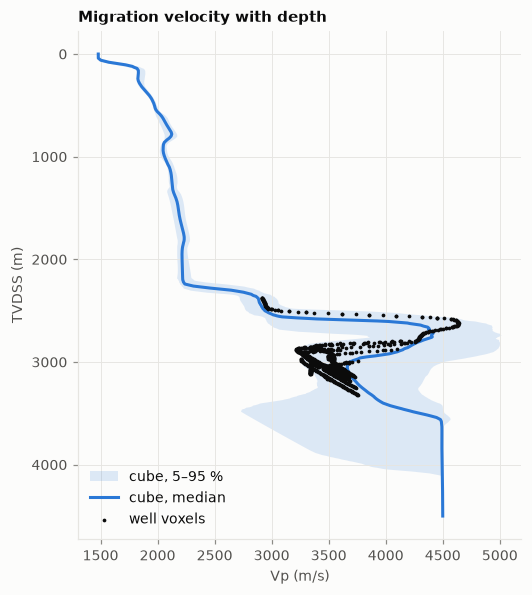

In [6]:
sub = np.asarray(vp[:, ::4, ::4], dtype=np.float32).reshape(vp.shape[0], -1)
p5, p50, p95 = np.percentile(sub, [5, 50, 95], axis=1)
z = np.asarray(g['depths'])
vw = np.asarray(vp[vox.IZ.values, vox.IY.values, vox.IX.values])

fig, ax = plt.subplots(figsize=(5.2, 6))
ax.fill_betweenx(z, p5, p95, color=vs.BLUE, alpha=0.15, linewidth=0, label='cube, 5–95 %')
ax.plot(p50, z, color=vs.BLUE, label='cube, median')
ax.scatter(vw, vox.TVDSS, s=6, color=vs.INK, linewidth=0, label='well voxels', zorder=3)
ax.invert_yaxis()
ax.set_xlabel('Vp (m/s)')
ax.set_ylabel('TVDSS (m)')
ax.set_title('Migration velocity with depth')
ax.grid(True)
ax.legend(loc='lower left')
fig.savefig(f'{FIG}/vp_depth.png')
plt.show()

## Cube values against porosity

Each dot is a well voxel and all wells are pooled. The pooled correlation mixes
differences between wells with variation inside each well, so the per-well values below
the figure tell more.

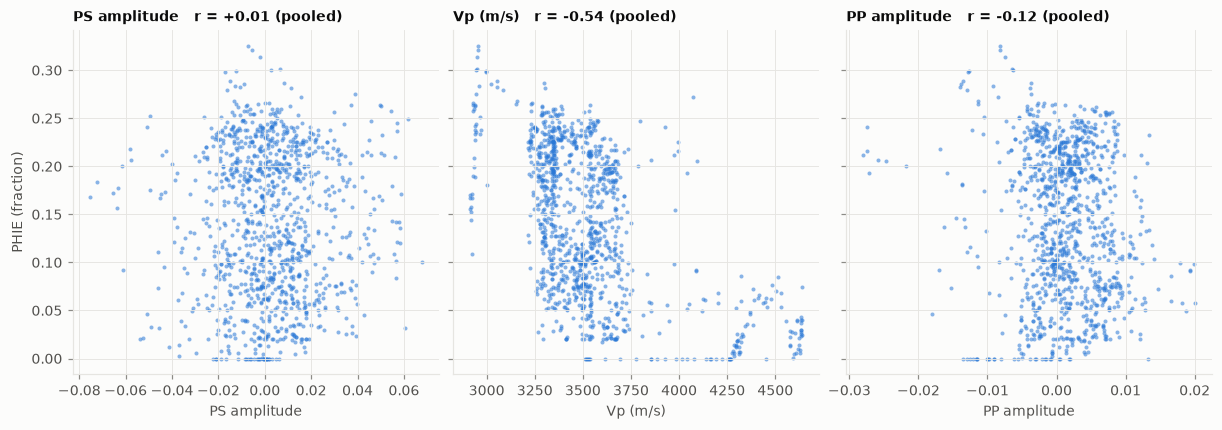

In [7]:
feat = pd.DataFrame({'PS amplitude': np.asarray(amp[vox.IZ, vox.IY, vox.IX]),
                     'Vp (m/s)': vw,
                     'PP amplitude': np.asarray(pp[vox.IZ, vox.IY, vox.IX]),
                     'PHIE': vox.PHIE.values, 'well': vox.wellbore.map(short).values})

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True, constrained_layout=True)
for ax, col in zip(axes, ['PS amplitude', 'Vp (m/s)', 'PP amplitude']):
    r = np.corrcoef(feat[col], feat.PHIE)[0, 1]
    ax.scatter(feat[col], feat.PHIE, s=7, color=vs.BLUE, alpha=0.55, linewidth=0)
    ax.set_xlabel(col)
    ax.set_title(f'{col}   r = {r:+.2f} (pooled)', fontsize=9)
    ax.grid(True)
axes[0].set_ylabel('PHIE (fraction)')
fig.savefig(f'{FIG}/crossplots.png')
plt.show()

In [8]:
per_well = (feat.groupby('well')
                .apply(lambda d: pd.Series({c: np.corrcoef(d[c], d.PHIE)[0, 1]
                                            for c in ['PS amplitude', 'Vp (m/s)', 'PP amplitude']}),
                       include_groups=False)
                .round(2))
per_well['voxels'] = feat.groupby('well').size()
per_well

,PS amplitude,Vp (m/s),PP amplitude,voxels
well,,,,
19 A,-0.25,0.52,-0.50,68
19 SR,0.06,-0.81,-0.21,217
F-1,-0.49,-0.22,-0.23,65
F-11A,-0.43,0.02,-0.32,36
F-11B,0.13,-0.39,-0.20,207
F-11T2,-0.06,0.13,0.06,46
F-12,-0.12,-0.03,-0.28,77
F-15D,-0.42,-0.19,-0.18,160
F-1A,0.65,-0.10,-0.33,46


The per-well correlations change sign from one well to the next. A single cube value at a
point is a weak and unstable predictor of porosity here. That fits the limitations listed in
the README: the PS image is converted-wave, the tie has no synthetic, and there are few
wells. Context windows, several cubes, and well-grouped validation are where to start.

*Contains data from the Volve field dataset, provided by Equinor ASA and the former Volve
licence partners ExxonMobil Exploration & Production Norway AS and Bayerngas Norge AS, under
the Equinor Open Data Licence.*